# Risk Prediction Overview

## Phase 0: Directory location

In [1]:
import sys
from pathlib import Path

# Add the project root to Python path
project_root = Path.cwd().parent  # Goes up one level from notebooks/
sys.path.insert(0, str(project_root))

## Phase 1: Modules linked

In [30]:
# 1. Enable Auto-reloading
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# 2. Import your heavy logic from your Python file
from core.gnn_layer.risk_predict import (
    fetch_graph_from_neo4j, 
    RiskEscalationGNN, 
    train_model, 
    evaluate_model
)

print("Environment linked and modules loaded successfully!")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Environment linked and modules loaded successfully!


## Phase 2: Fetching data

In [34]:
from core.config import graph_base
print("Fetching graph data from Neo4j...")
# UPDATE THIS with your actual Docker Neo4j password

baseline_data, enriched_data, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data.num_nodes} nodes and {baseline_data.num_edges} edges.")

print(f"Total High-Risk Edges (Class 1): {int(enriched_data.y.sum().item())}")

Fetching graph data from Neo4j...
Successfully loaded 45 nodes and 87 edges.
Total High-Risk Edges (Class 1): 4


## Phase 3: Initialize and train models

In [35]:
# Initialize
baseline_model = RiskEscalationGNN(num_node_features=1, hidden_channels=16)
enriched_model = RiskEscalationGNN(num_node_features=3, hidden_channels=16)

# Train
print("--- Training Baseline Model ---")
trained_baseline = train_model(baseline_model, baseline_data, epochs=100)

print("\n--- Training Enriched Model ---")
trained_enriched = train_model(enriched_model, enriched_data, epochs=100)

--- Training Baseline Model ---
Epoch 000 | Loss: 0.7000
Epoch 020 | Loss: 0.2256
Epoch 040 | Loss: 0.1968
Epoch 060 | Loss: 0.1603
Epoch 080 | Loss: 0.1680

--- Training Enriched Model ---
Epoch 000 | Loss: 0.7408
Epoch 020 | Loss: 0.1533
Epoch 040 | Loss: 0.1586
Epoch 060 | Loss: 0.1304
Epoch 080 | Loss: 0.1210


## Phase 4: Chart

FINAL ABLATION STUDY RESULTS:
Baseline GNN -> AUC: 0.518 | Recall: 0.000
Enriched KG  -> AUC: 0.917 | Recall: 0.000


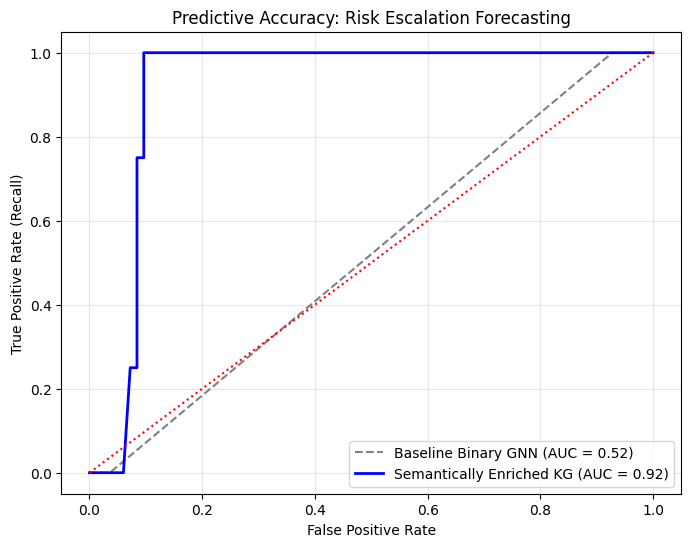

In [37]:
# Evaluate
base_auc, base_recall, y_true_b, preds_b = evaluate_model(trained_baseline, baseline_data)
enr_auc, enr_recall, y_true_e, preds_e = evaluate_model(trained_enriched, enriched_data)

print("="*30)
print("FINAL ABLATION STUDY RESULTS:")
print("="*30)
print(f"Baseline GNN -> AUC: {base_auc:.3f} | Recall: {base_recall:.3f}")
print(f"Enriched KG  -> AUC: {enr_auc:.3f} | Recall: {enr_recall:.3f}")

# Plotting the ROC Curve
fpr_b, tpr_b, _ = roc_curve(y_true_b, preds_b)
fpr_e, tpr_e, _ = roc_curve(y_true_e, preds_e)

plt.figure(figsize=(8, 6))
plt.plot(fpr_b, tpr_b, linestyle='--', color='gray', label=f'Baseline Binary GNN (AUC = {base_auc:.2f})')
plt.plot(fpr_e, tpr_e, color='blue', linewidth=2, label=f'Semantically Enriched KG (AUC = {enr_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle=':') 

plt.title('Predictive Accuracy: Risk Escalation Forecasting')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

# Save and show
plt.savefig('gnn_ablation_study_results.png', dpi=300, bbox_inches='tight')
plt.show()

## Final report

In [25]:
# Import your new function
from core.gnn_layer.risk_predict import generate_threat_report

print("==========================================================")
print("  GNN THREAT ESCALATION REPORT (ENRICHED KG)  ")
print("==========================================================\n")

# Generate alerts for any relationship with > 75% escalation probability
threat_alerts = generate_threat_report(trained_enriched, enriched_data, reverse_mapping, threshold=0.75)

if not threat_alerts:
    print("✅ No high-risk escalations detected in the current network topology.")
else:
    for alert in threat_alerts:
        print(f"⚠️ HIGH RISK ({alert['probability']:.1f}%): {alert['source']} -> {alert['target']}")

  GNN THREAT ESCALATION REPORT (ENRICHED KG)  

✅ No high-risk escalations detected in the current network topology.
